# Phase 1 — Exploring FastF1 Data

**Goal of this notebook:** see the raw data with your own eyes *before* trusting any
pipeline that processes it.

This is not a formality. Every design decision in `app/ingestion/transform.py` came from
something visible in this notebook, and two of them came from things that contradicted
reasonable assumptions. Run the cells, look at the output, and you'll understand why the
database schema looks the way it does.

**What you'll learn here:**
1. Why lap times are stored as integer milliseconds, not seconds
2. Why `TrackStatus` is an array in our schema and not a number ← *the big one*
3. What `IsAccurate` buys you for free
4. Why `Compound` alone is not enough to model tires
5. Why `TyreLife` doesn't start at zero
6. Why pit stop duration had to be derived, and why it's sometimes NULL

In [1]:
import warnings, logging
warnings.filterwarnings('ignore')

import fastf1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# FastF1 logs every cache hit at INFO, which drowns the output we care about.
logging.getLogger('fastf1').setLevel(logging.ERROR)
for _name in ('fastf1.core', 'fastf1.api', 'fastf1._api', 'fastf1.req'):
    logging.getLogger(_name).setLevel(logging.ERROR)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)

# Cache every HTTP response. Without this, each re-run re-downloads the
# session -- slow for you and rude to the upstream API.
fastf1.Cache.enable_cache('../data/fastf1_cache')
print('fastf1', fastf1.__version__)

fastf1 3.8.3


## 1. Load a session

`telemetry=False` is the single most important argument here. Telemetry is per-car data at
4–10 Hz — hundreds of thousands of rows per session. None of this project's four features
need it, and skipping it turns a ~40 second load into a ~3 second one.

We start with the **2024 Italian Grand Prix** (Monza): a dry, clean race. Clean data first,
then we'll deliberately break our assumptions with a messier race.

In [2]:
session = fastf1.get_session(2024, 'Monza', 'R')
session.load(telemetry=False, weather=True, messages=False)

laps = session.laps
print(f'{len(laps)} laps, {laps.Driver.nunique()} drivers, {session.total_laps} scheduled laps')

1008 laps, 20 drivers, 53 scheduled laps


In [3]:
# Look at the columns and their dtypes. The dtypes matter more than you'd think.
laps.dtypes

Time                  timedelta64[ns]
Driver                         object
DriverNumber                   object
LapTime               timedelta64[ns]
LapNumber                     float64
Stint                         float64
PitOutTime            timedelta64[ns]
PitInTime             timedelta64[ns]
Sector1Time           timedelta64[ns]
Sector2Time           timedelta64[ns]
Sector3Time           timedelta64[ns]
Sector1SessionTime    timedelta64[ns]
Sector2SessionTime    timedelta64[ns]
Sector3SessionTime    timedelta64[ns]
SpeedI1                       float64
SpeedI2                       float64
SpeedFL                       float64
SpeedST                       float64
IsPersonalBest                   bool
Compound                       object
TyreLife                      float64
FreshTyre                        bool
Team                           object
LapStartTime          timedelta64[ns]
LapStartDate           datetime64[ns]
TrackStatus                    object
Position    

## 2. Gotcha 1 — lap times are Timedeltas, and often missing

`LapTime` is a `pandas.Timedelta`, not a number. You cannot put a Timedelta in a database
column and expect arithmetic to work, so we convert to **integer milliseconds**.

Why integer ms and not float seconds? Floats introduce rounding error that accumulates when
you sum 50+ laps to a race time (Phase 3 does exactly this), and float equality is unreliable.
Integer ms is exact.

Notice also how often timing data is simply absent.

In [4]:
key = ['LapTime','Sector1Time','Sector2Time','Sector3Time','Compound','TyreLife','Position']
missing = laps[key].isna().sum().to_frame('missing_count')
missing['missing_pct'] = (missing.missing_count / len(laps) * 100).round(1)
print(missing)
print()
print('A single LapTime value:', repr(laps.LapTime.dropna().iloc[0]))
print('Its type:            ', type(laps.LapTime.dropna().iloc[0]))

             missing_count  missing_pct
LapTime                  0          0.0
Sector1Time             20          2.0
Sector2Time              0          0.0
Sector3Time              0          0.0
Compound                 0          0.0
TyreLife                 0          0.0
Position                 0          0.0

A single LapTime value: Timedelta('0 days 00:01:28.179000')
Its type:             <class 'pandas._libs.tslibs.timedeltas.Timedelta'>


In [5]:
# This is what transform.td_to_ms does:
from app.ingestion.transform import td_to_ms

sample = laps.LapTime.iloc[:3].tolist() + [pd.NaT]
for value in sample:
    print(f'{str(value):<30} -> {td_to_ms(value)}')

print()
print('NaT becomes None (SQL NULL), NOT 0. A missing lap time is unknown,')
print('not instantaneous -- storing 0 would corrupt every average.')

0 days 00:01:28.179000         -> 88179
0 days 00:01:25.396000         -> 85396
0 days 00:01:25.179000         -> 85179
NaT                            -> None

NaT becomes None (SQL NULL), NOT 0. A missing lap time is unknown,
not instantaneous -- storing 0 would corrupt every average.


## 3. Gotcha 2 — `TrackStatus` is a flag string, not a number

**This is the most important cell in the notebook.**

Monza 2024 was a clean race, so its `TrackStatus` is uninformative — look:

In [6]:
print('Monza 2024 TrackStatus values:')
print(laps.TrackStatus.value_counts())
print()
print('All clear. This race tells us nothing about the problem. So load a messy one.')

Monza 2024 TrackStatus values:
TrackStatus
1    1008
Name: count, dtype: int64

All clear. This race tells us nothing about the problem. So load a messy one.


In [7]:
# Brazil 2024: wet, multiple safety cars, and a red flag.
brazil = fastf1.get_session(2024, 'Brazil', 'R')
brazil.load(telemetry=False, weather=False, messages=False)

print('São Paulo 2024 TrackStatus values:')
print(brazil.laps.TrackStatus.value_counts())

São Paulo 2024 TrackStatus values:
TrackStatus
1       806
12      153
4        48
21       26
14       18
45       17
124      16
671      15
41       15
126      14
26        1
51        1
1267      1
2671      1
267       1
71        1
Name: count, dtype: int64


Look carefully at those values: `'12'`, `'45'`, `'124'`, `'671'`, `'1267'`.

These are **not numbers**. FastF1 concatenates every status flag that applied during the lap
into one string. The single digits mean:

| flag | meaning |
|---|---|
| 1 | track clear |
| 2 | yellow flag |
| 4 | safety car |
| 5 | red flag |
| 6 | virtual safety car deployed |
| 7 | virtual safety car ending |

So `'14'` means the lap was **partly clear and partly under safety car**. And `'1267'` means
clear, yellow, VSC deployed and VSC ending all happened during that one lap.

### The bug this creates

If you call `int(track_status)` — which looks entirely reasonable — `'1267'` becomes the
integer **1267**. Not an error. Not a warning. Just a plausible-looking number that is
complete nonsense, silently poisoning every model you train on it.

This is the kind of bug that doesn't crash; it just makes your results quietly wrong.

In [8]:
from app.ingestion.transform import parse_track_status, is_green_flag

print(f"{'raw':>8} | {'int() -- WRONG':>16} | {'parsed -- CORRECT':<18} | green?")
print('-' * 68)
for raw in ['1', '12', '14', '45', '1267', '21']:
    print(f'{raw:>8} | {int(raw):>16} | {str(parse_track_status(raw)):<18} | {is_green_flag(parse_track_status(raw))}')

     raw |   int() -- WRONG | parsed -- CORRECT  | green?
--------------------------------------------------------------------
       1 |                1 | [1]                | True
      12 |               12 | [1, 2]             | False
      14 |               14 | [1, 4]             | False
      45 |               45 | [4, 5]             | False
    1267 |             1267 | [1, 2, 6, 7]       | False
      21 |               21 | [1, 2]             | False


### Two subtleties in the parser

**It sorts the digits.** FastF1 emits both `'12'` and `'21'` for the same pair of flags. Without
sorting, Postgres would store `{1,2}` and `{2,1}` as *distinct* arrays, and a `GROUP BY` would
split one real condition into two buckets. We found this in real data — it accounted for 26 laps
being miscounted at São Paulo.

**`is_green_flag` requires exactly `[1]`.** A yellow-flag lap (`[1,2]`) is *not* green: drivers
lifted for a local caution, so the lap time isn't representative. For tire-degradation modeling a
contaminated lap is worse than a missing one, so we're strict.

In [9]:
# How much data does strictness cost us?
status = brazil.laps.TrackStatus.apply(parse_track_status)
green = status.apply(is_green_flag)
non_green_flags = status.apply(lambda s: bool(s) and any(f in (4,5,6,7) for f in s))

print(f'São Paulo 2024, {len(brazil.laps)} laps total:')
print(f'  strictly clear [1]        : {green.sum():>5} ({green.mean():.0%})')
print(f'  SC / red / VSC involved   : {non_green_flags.sum():>5} ({non_green_flags.mean():.0%})')
print(f'  yellow but no SC          : {(~green & ~non_green_flags).sum():>5}')
print()
print('Roughly a third of this race is unusable for pace modeling.')
print('That is the correct answer, not a problem to engineer around.')

São Paulo 2024, 1134 laps total:
  strictly clear [1]        :   806 (71%)
  SC / red / VSC involved   :   149 (13%)
  yellow but no SC          :   179

Roughly a third of this race is unusable for pace modeling.
That is the correct answer, not a problem to engineer around.


## 4. Gotcha 3 — `IsAccurate` is free quality control

FastF1 computes its own flag for "this lap is clean enough to compare": it excludes in-laps,
out-laps, and laps where timing was incomplete. Filtering on it removes most of the garbage
in one step, and it catches things `TrackStatus` does not.

In [10]:
print(f"{'session':<14} {'laps':>6} {'accurate':>9} {'pct':>6}")
for label, frame in [('Monza (dry)', laps), ('São Paulo (wet)', brazil.laps)]:
    acc = frame.IsAccurate.sum()
    print(f'{label:<14} {len(frame):>6} {acc:>9} {acc/len(frame):>6.0%}')

print()
print('The two filters are not redundant -- combine them:')
combined = brazil.laps[brazil.laps.IsAccurate & green]
print(f'  São Paulo accurate AND strictly green: {len(combined)} of {len(brazil.laps)} laps')

session          laps  accurate    pct
Monza (dry)      1008       927    92%
São Paulo (wet)   1134       943    83%

The two filters are not redundant -- combine them:
  São Paulo accurate AND strictly green: 800 of 1134 laps


## 5. Gotcha 4 — `Compound` is relative, not absolute

F1 tires come in dry compounds C1 (hardest) to C5 (softest). Each weekend Pirelli picks three
of them, and *those three* get labelled SOFT / MEDIUM / HARD for that event.

**FastF1 only gives you the relative label.** So "SOFT" at Monza and "SOFT" at Monaco are
physically different rubber with different degradation behaviour.

**Consequence for Phase 2:** a model with `compound` as a feature and no circuit interaction is
learning an average over physically unlike things. Compound must always be modeled *with* circuit.

In [11]:
# Same label, different circuits, different pace profile.
for name, frame in [('Monza', laps), ('São Paulo', brazil.laps)]:
    clean = frame[frame.IsAccurate & frame.TrackStatus.apply(lambda s: parse_track_status(s) == [1])]
    summary = clean.groupby('Compound').LapTime.agg(
        laps='count',
        fastest_s=lambda s: round(s.min().total_seconds(), 2),
        median_s=lambda s: round(s.median().total_seconds(), 2),
    )
    print(f'--- {name} ---')
    print(summary)
    print()

--- Monza ---
          laps  fastest_s  median_s
Compound                           
HARD       686      81.43     84.72
MEDIUM     240      81.75     85.21
SOFT         1      82.23     82.23

--- São Paulo ---
              laps  fastest_s  median_s
Compound                               
INTERMEDIATE   799      80.47     84.41
WET              1     101.66    101.66



## 6. Gotcha 5 — `TyreLife` does not start at zero

`TyreLife` counts laps on that **tire set**, including laps from *earlier sessions*. A "new" race
tire that did a qualifying run already has mileage on it. `FreshTyre` tells you whether the set
was genuinely new when the stint began.

Phase 2 cares about this because tire age is the model's main input — getting its origin wrong
shifts every degradation estimate.

In [12]:
stints = (laps.groupby(['Driver','Stint'])
          .agg(compound=('Compound','first'),
               lap_start=('LapNumber','min'),
               lap_end=('LapNumber','max'),
               life_start=('TyreLife','min'),
               life_end=('TyreLife','max'),
               fresh=('FreshTyre','first'))
          .reset_index())

print('Stints that did NOT start on a brand-new set:')
print(stints[~stints.fresh].head(10).to_string(index=False))
print()
print('Stints starting above TyreLife 1:', (stints.life_start > 1).sum(), 'of', len(stints))

Stints that did NOT start on a brand-new set:
Driver  Stint compound  lap_start  lap_end  life_start  life_end  fresh
   ALO    1.0   MEDIUM        1.0     12.0         2.0      13.0  False
   ALO    2.0     HARD       13.0     35.0         2.0      24.0  False
   ALO    3.0     HARD       36.0     53.0         3.0      20.0  False
   BOT    1.0     HARD        1.0     33.0         2.0      34.0  False
   BOT    2.0   MEDIUM       34.0     52.0         2.0      20.0  False
   RIC    2.0     HARD       12.0     53.0         2.0      43.0  False
   STR    1.0     HARD        1.0     19.0         2.0      20.0  False
   STR    2.0     HARD       20.0     36.0         3.0      19.0  False
   STR    3.0   MEDIUM       37.0     50.0         2.0      15.0  False
   TSU    1.0     HARD        1.0      7.0         2.0       8.0  False

Stints starting above TyreLife 1: 12 of 50


## 7. Gotcha 6 — pit stop duration must be derived, and sometimes can't be

FastF1 gives no pit stop duration. It gives `PitInTime` on the in-lap and `PitOutTime` on the
*following* out-lap, both as session-time offsets.

The obvious move is `PitOutTime - PitInTime`. Watch what that produces at São Paulo.

In [13]:
ver = brazil.laps.pick_drivers('VER').sort_values('LapNumber')
pit_laps = ver[ver.PitInTime.notna() | ver.PitOutTime.notna()]
print(pit_laps[['LapNumber','Stint','Compound','LapTime','PitInTime','PitOutTime','TrackStatus']].to_string(index=False))

pit_in = pit_laps.PitInTime.dropna().iloc[0]
pit_out = pit_laps.PitOutTime.dropna().iloc[0]
naive = (pit_out - pit_in).total_seconds()
print()
print(f'Naive duration: {naive:.0f} seconds  =  {naive/60:.0f} MINUTES')
print()
print('A pit stop is ~25 seconds. This is a red-flag race suspension that happened')
print('while cars sat in the pit lane. Averaging this into a pit-loss estimate would')
print('wreck Phase 3 -- and it would never raise an error.')

 LapNumber  Stint     Compound LapTime              PitInTime             PitOutTime TrackStatus
      32.0    1.0 INTERMEDIATE     NaT 0 days 02:00:37.713000                    NaT          45
      33.0    2.0 INTERMEDIATE     NaT                    NaT 0 days 02:24:06.937000          12

Naive duration: 1409 seconds  =  23 MINUTES

A pit stop is ~25 seconds. This is a red-flag race suspension that happened
while cars sat in the pit lane. Averaging this into a pit-loss estimate would
wreck Phase 3 -- and it would never raise an error.


In [14]:
# So derive_pit_stops() records the stop but NULLs any implausible duration.
from app.ingestion.transform import derive_pit_stops, PIT_DURATION_MIN_MS, PIT_DURATION_MAX_MS

print(f'accepted range: {PIT_DURATION_MIN_MS/1000:.0f}s to {PIT_DURATION_MAX_MS/1000:.0f}s')
print()
for name, sess in [('Monza', session), ('São Paulo', brazil)]:
    ids = {d: i for i, d in enumerate(sess.laps.Driver.unique())}
    stops = derive_pit_stops(sess.laps, 1, ids)
    durations = [s['duration_ms_est'] for s in stops if s['duration_ms_est']]
    print(f'{name:<11} {len(stops):>3} stops, {len(durations):>3} with a trusted duration', end='')
    if durations:
        print(f', median {np.median(durations)/1000:.1f}s')
    else:
        print()

print()
print('Monza keeps nearly all of them (~26s median -- correct for F1).')
print('São Paulo loses half, which is the honest outcome for that race.')

accepted range: 8s to 180s

Monza        31 stops,  30 with a trusted duration, median 24.8s
São Paulo    36 stops,  18 with a trusted duration, median 25.8s

Monza keeps nearly all of them (~26s median -- correct for F1).
São Paulo loses half, which is the honest outcome for that race.


## 8. What the degradation signal actually looks like

Phase 2's whole job is to model the next plot. Each line is one stint: lap time against tire age.

Watch for the thing that makes this hard — described below the chart.

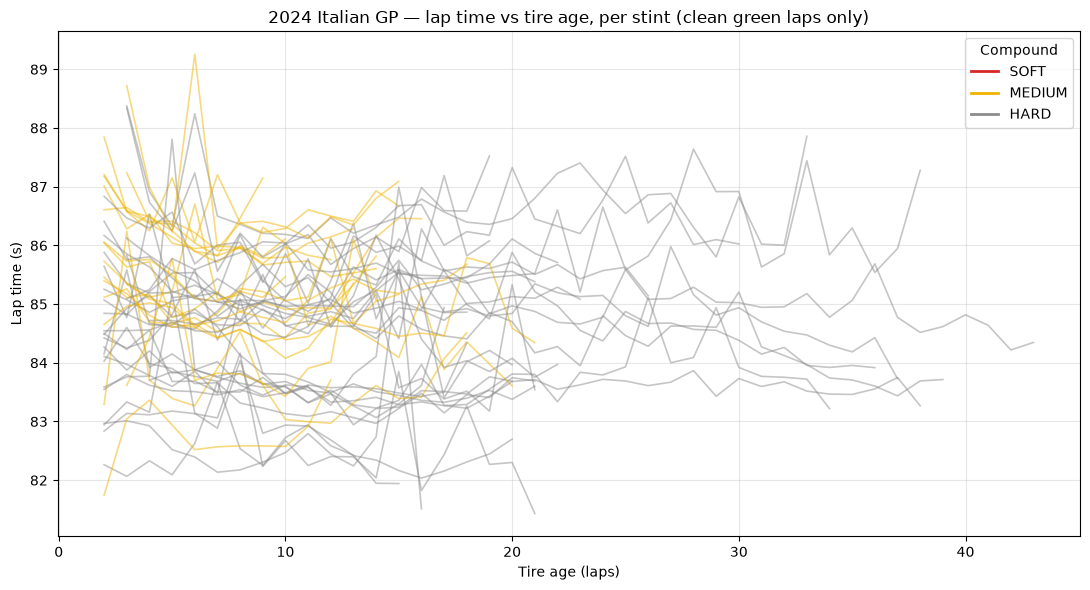

In [15]:
fig, ax = plt.subplots(figsize=(11, 6))

clean = laps[laps.IsAccurate & laps.TrackStatus.apply(lambda s: parse_track_status(s) == [1])]
colors = {'SOFT': '#d62728', 'MEDIUM': '#f0b400', 'HARD': '#8c8c8c'}

for (driver, stint), group in clean.groupby(['Driver','Stint']):
    if len(group) < 8:
        continue
    group = group.sort_values('TyreLife')
    ax.plot(group.TyreLife, group.LapTime.dt.total_seconds(),
            alpha=0.5, linewidth=1.2,
            color=colors.get(group.Compound.iloc[0], '#1f77b4'))

for compound, color in colors.items():
    ax.plot([], [], color=color, label=compound, linewidth=2)

ax.set_xlabel('Tire age (laps)')
ax.set_ylabel('Lap time (s)')
ax.set_title('2024 Italian GP — lap time vs tire age, per stint (clean green laps only)')
ax.legend(title='Compound')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### The confound at the heart of Phase 2

Many of those lines slope **downward** -- laps getting *faster* as the tire ages. Tires do not
improve with age, so something else is moving the lap time. In fact **two** things are, and
separating them is the real work of Phase 2.

**1. Fuel burn (every race).** A car starts with ~110 kg of fuel and burns roughly 2 kg per lap.
Less weight means more speed -- about 0.03 s per kg, so roughly **0.06 s/lap of gain**. Tire
degradation is often a similar magnitude in the *opposite* direction, so the two partly cancel.

**2. Track evolution (worse in the wet).** A drying track gets faster lap after lap, and rubber
laid down over a dry session does the same thing more gently. In the cell below you will see the
wet INTERMEDIATE stints show far steeper negative slopes than the dry ones -- that gap is mostly
the track drying, not the tires.

So a raw fit measures *degradation minus fuel effect minus track evolution*, and reports it as
if it were degradation. **You will underestimate tire wear**, and nothing will warn you: the
model fits well, the residuals look fine, and the answer is wrong.

Phase 2 handles these in order -- fuel-correct first (it is simple arithmetic), then restrict to
dry compounds so track evolution is a small effect rather than a dominant one. The general
lesson is statistical, not automotive: **confounded variables do not announce themselves, and a
model cannot tell you about a variable you never gave it.**

## 9. Query what you ingested

Everything above is now in Postgres. Same data, queried through the API's data layer.

In [16]:
from sqlalchemy import text
from app.db.base import engine

with engine.connect() as conn:
    print('--- rows per table ---')
    for table in ['seasons','events','sessions','drivers','laps','weather','pit_stops']:
        n = conn.execute(text(f'SELECT count(*) FROM raw.{table}')).scalar()
        print(f'  raw.{table:<12} {n:>7,}')

    print()
    print('--- track_status stored as real arrays ---')
    rows = conn.execute(text("""
        SELECT track_status, count(*) AS laps
        FROM raw.laps GROUP BY 1 ORDER BY 2 DESC LIMIT 6
    """)).all()
    for status, n in rows:
        print(f'  {str(status):<16} {n:>5}')

--- rows per table ---
  raw.seasons            2
  raw.events            46
  raw.sessions          92
  raw.drivers           25
  raw.laps          66,033
  raw.weather       11,238
  raw.pit_stops      6,065

--- track_status stored as real arrays ---
  [1]              60236
  [1, 2]            2603
  [4]                995
  [1, 4]             568
  [1, 2, 5]          414
  [1, 2, 4]          362


In [17]:
# The Phase 2 modeling query, in SQL. `= ARRAY[1]` is the strict green filter.
import pandas as pd

stint_laps = pd.read_sql(text("""
    SELECT e.event_name, d.abbreviation AS driver, l.stint_number,
           l.compound, l.tyre_life, l.lap_time_ms / 1000.0 AS lap_time_s
    FROM raw.laps l
    JOIN raw.sessions s ON s.id = l.session_id
    JOIN raw.events   e ON e.id = s.event_id
    JOIN raw.drivers  d ON d.id = l.driver_id
    WHERE s.session_type = 'R'
      AND l.is_accurate
      AND l.track_status = ARRAY[1]::smallint[]
      AND l.lap_time_ms IS NOT NULL
    ORDER BY e.event_name, d.abbreviation, l.stint_number, l.tyre_life
"""), engine)

print(f'{len(stint_laps):,} clean modeling rows available')
stint_laps.head(10)

43,540 clean modeling rows available


,event_name,driver,stint_number,compound,tyre_life,lap_time_s
0,Abu Dhabi Grand Prix,ALB,1,MEDIUM,3.0,93.560
1,Abu Dhabi Grand Prix,ALB,1,MEDIUM,4.0,90.060
2,Abu Dhabi Grand Prix,ALB,1,MEDIUM,4.0,91.768
3,Abu Dhabi Grand Prix,ALB,1,MEDIUM,5.0,91.591
4,Abu Dhabi Grand Prix,ALB,1,MEDIUM,5.0,90.369
5,Abu Dhabi Grand Prix,ALB,1,MEDIUM,6.0,91.422
6,Abu Dhabi Grand Prix,ALB,1,MEDIUM,6.0,90.815
7,Abu Dhabi Grand Prix,ALB,1,MEDIUM,7.0,90.317
8,Abu Dhabi Grand Prix,ALB,1,MEDIUM,7.0,91.491
9,Abu Dhabi Grand Prix,ALB,1,MEDIUM,8.0,91.438


## 10. A first degradation estimate, by hand

Before any ML, fit one straight line to one stint with `numpy.polyfit`. The slope is the
degradation rate in seconds per lap.

This is a complete, usable model. Phase 2 Stage A formalises it; everything after that is an
attempt to beat it. Knowing what the simplest possible answer looks like is how you'll tell
whether a gradient-booster is actually earning its complexity.

In [18]:
groups = stint_laps.groupby(['event_name','driver','stint_number','compound'])

rows = []
for (event, driver, stint, compound), g in groups:
    if len(g) < 10:
        continue
    slope, intercept = np.polyfit(g.tyre_life.astype(float), g.lap_time_s.astype(float), 1)
    rows.append({'event': event, 'driver': driver, 'stint': int(stint),
                 'compound': compound, 'laps': len(g),
                 'deg_s_per_lap': round(slope, 4), 'base_s': round(intercept, 3)})

fits = pd.DataFrame(rows)
fits['condition'] = np.where(fits.compound.isin(['INTERMEDIATE','WET']), 'wet', 'dry')

print('Median raw slope by condition (NOT fuel-corrected):')
print(fits.groupby('condition').deg_s_per_lap.agg(['count','median','min','max']).round(4))
print()
print('Dry stints only, slowest-degrading first:')
dry = fits[fits.condition == 'dry'].sort_values('deg_s_per_lap')
print(dry[['driver','stint','compound','laps','deg_s_per_lap','base_s']].to_string(index=False))
print()
neg = (fits.deg_s_per_lap < 0).mean()
print(f'{neg:.0%} of all stints have a NEGATIVE slope -- i.e. lap times')
print('improving as the tire ages, which is physically impossible.')

Median raw slope by condition (NOT fuel-corrected):
           count  median     min     max
condition                               
dry         1459  0.0016 -3.5254  0.7122
wet           92 -0.3860 -1.0605  0.1944

Dry stints only, slowest-degrading first:
driver  stint compound  laps  deg_s_per_lap  base_s
   SAR      1     SOFT    13        -3.5254 120.711
   PIA      1     SOFT    13        -3.2925 115.312
   HUL      1     SOFT    13        -3.2519 116.026
   BOT      1     SOFT    26        -1.5845  96.479
   ALO      3     HARD    11        -1.3801 104.845
   HAM      3     SOFT    14        -1.3387  95.706
   RUS      3     SOFT    15        -0.9055  90.453
   PER      3     SOFT    16        -0.8264  89.590
   STR      3     SOFT    18        -0.7630  89.892
   VER      3     SOFT    23        -0.5920  88.033
   NOR      3     SOFT    23        -0.5768  86.105
   ALO      3     SOFT    21        -0.5687  87.218
   SAR      2     HARD    19        -0.5551 107.651
   MAG      2

## 11. The filters are not enough -- and this is the finding that matters most

We now have two filters we trust: `is_accurate` and `track_status = [1]`. They look thorough.

They are not. Run the next cell.

In [19]:
# Laps that pass BOTH filters yet are absurdly slow for their session.
suspect = pd.read_sql(text("""
    WITH clean AS (
      SELECT l.session_id, l.lap_number, l.lap_time_ms, l.tyre_life,
             l.compound, l.stint_number, l.track_status, l.is_accurate,
             e.season_year, e.event_name, d.abbreviation AS driver
      FROM raw.laps l
      JOIN raw.sessions s ON s.id = l.session_id AND s.session_type = 'R'
      JOIN raw.events   e ON e.id = s.event_id
      JOIN raw.drivers  d ON d.id = l.driver_id
      WHERE l.is_accurate
        AND l.track_status = ARRAY[1]::smallint[]
        AND l.lap_time_ms IS NOT NULL
    ),
    medians AS (
      SELECT session_id,
             percentile_cont(0.5) WITHIN GROUP (ORDER BY lap_time_ms) AS med
      FROM clean GROUP BY session_id
    )
    SELECT c.season_year, c.event_name, c.driver, c.lap_number, c.stint_number,
           c.compound, c.tyre_life,
           round(c.lap_time_ms/1000.0, 1)  AS lap_s,
           round((m.med/1000.0)::numeric, 1)          AS session_median_s,
           round((c.lap_time_ms / m.med)::numeric, 2) AS ratio,
           c.track_status, c.is_accurate
    FROM clean c JOIN medians m USING (session_id)
    WHERE c.lap_time_ms > m.med * 1.5
    ORDER BY ratio DESC
"""), engine)

print(f'{len(suspect)} laps pass both filters while being >150% of their session median:')
print()
print(suspect.head(10).to_string(index=False))

17 laps pass both filters while being >150% of their session median:

 season_year             event_name driver  lap_number  stint_number compound  tyre_life  lap_s  session_median_s  ratio track_status  is_accurate
        2023 Mexico City Grand Prix    PIA          36             3   MEDIUM        5.0  148.5              83.9   1.77          [1]         True
        2023   São Paulo Grand Prix    VER           4             3     SOFT        5.0  132.7              76.2   1.74          [1]         True
        2023   São Paulo Grand Prix    NOR           4             3     SOFT        2.0  130.9              76.2   1.72          [1]         True
        2023 Mexico City Grand Prix    TSU          36             3     HARD        2.0  141.6              83.9   1.69          [1]         True
        2023 Mexico City Grand Prix    RUS          36             3   MEDIUM        7.0  141.2              83.9   1.68          [1]         True
        2023 Mexico City Grand Prix    HUL      

Look at the top row. A lap recorded at roughly **148 seconds** where the session median is about
**83 seconds** -- 65 seconds off the pace -- and it carries `track_status = [1]` and
`is_accurate = True`. Both of our filters wave it through.

**What it actually is:** the standing-restart lap after a red flag. Mexico City 2023 was stopped,
cars formed up on the grid, and the lap timer kept running while they sat stationary. By the time
the lap was recorded the track status had already reverted to clear.

The data is not wrong. That genuinely was the elapsed time for that lap. Our *filters* are wrong,
because neither of them models "the race was stopped and restarted."

### Why 17 laps matter

There are only 17 of these in 46 races -- 0.03% of the data. It is tempting to ignore them.

Don't. Ordinary least squares minimises *squared* error, so a point 65 s from the trend exerts
enormous leverage. One such lap inside a 34-lap stint is enough to drag the fitted slope from
roughly −0.02 s/lap to −3.5 s/lap. That is where the absurd outliers in the next cell come from.

In [20]:
# Demonstrate the leverage: fit one contaminated stint with and without its outlier.
worst = suspect.iloc[0]
stint = stint_laps[
    (stint_laps.event_name == worst.event_name)
    & (stint_laps.driver == worst.driver)
    & (stint_laps.stint_number == worst.stint_number)
].copy()

x = stint.tyre_life.astype(float)
y = stint.lap_time_s.astype(float)
with_outlier, _ = np.polyfit(x, y, 1)

# Robust filter: drop laps more than 25% above the stint median.
keep = y <= y.median() * 1.25
without_outlier, _ = np.polyfit(x[keep], y[keep], 1)

print(f'{worst.event_name} {int(worst.season_year)} -- {worst.driver} stint {int(worst.stint_number)}')
print(f'  laps in stint                : {len(stint)}')
print(f'  laps dropped by pace filter  : {(~keep).sum()}')
print()
print(f'  slope WITH the restart lap   : {with_outlier:+.4f} s/lap   <- nonsense')
print(f'  slope WITHOUT it             : {without_outlier:+.4f} s/lap   <- plausible')
print()
print(f'One lap out of {len(stint)} changes the answer by a factor of'
      f' {abs(with_outlier/without_outlier):.0f}.')

Mexico City Grand Prix 2023 -- PIA stint 3
  laps in stint                : 34
  laps dropped by pace filter  : 1

  slope WITH the restart lap   : -0.3113 s/lap   <- nonsense
  slope WITHOUT it             : -0.0065 s/lap   <- plausible

One lap out of 34 changes the answer by a factor of 48.


### The lesson

**Two independent filters agreeing is not proof that your data is clean.** Both `is_accurate` and
the track-status filter encode assumptions about how a session behaves, and both assumptions
failed here in the same way, so their agreement told us nothing.

What caught it was looking at the **distribution of the target variable** and asking which values
are physically implausible. No categorical filter would have found this; a histogram does it
immediately.

So Phase 2 begins with three filters, not two:

1. `is_accurate` -- FastF1's own judgement
2. `track_status = [1]` -- strictly clear conditions
3. **a pace-based outlier rule** -- discard laps far above the stint median

`python -m app.ingestion.cli doctor` reports the count of laps in category 3 as a `[WARN]`, so it
stays visible as more seasons are ingested.

---

## What to take from this notebook

| # | Finding | Where it shows up in code |
|---|---|---|
| 1 | Lap times are Timedeltas, frequently `NaT` | `td_to_ms`, nullable `BIGINT` columns |
| 2 | `TrackStatus` is a multi-flag string | `parse_track_status` → `SMALLINT[]` |
| 3 | `IsAccurate` is free quality control | `is_accurate` column + API filter |
| 4 | `Compound` is relative to the weekend | Phase 2 must interact it with circuit |
| 5 | `TyreLife` carries over between sessions | `tyre_life` + `is_fresh_tyre` both stored |
| 6 | Pit duration is derived and sometimes untrustworthy | `derive_pit_stops` clamping |
| 7 | Fuel burn confounds degradation | **a first task of Phase 2** |
| 8 | `Compound` can be the literal string `"None"` | `to_str` sentinel handling + CHECK constraint |
| 9 | `session.date` is naive but already UTC | `_as_utc` |
| 10 | **Both filters still admit 148 s restart laps** | **pace filter required in Phase 2** |

The habit worth keeping: *look at the data before you model it.* Items 2, 6, 7, 8 and 10 would all
have produced working code with wrong answers, and none of them would have raised an error.

Item 10 is the one to remember: it was found by plotting the target variable's distribution, not by
reasoning about filters. Two filters agreeing is not evidence of clean data.

**Next:** `02_tire_degradation.ipynb` — fuel-correct these slopes, then build the model.